In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
DATA_DIR = Path("data")
COUNTRY_FILES = {
    "US": DATA_DIR / "USvideos.csv",
    "GB": DATA_DIR / "GBvideos.csv",
    "CA": DATA_DIR / "CAvideos.csv",
    "IN": DATA_DIR / "INvideos.csv",
}

frames = []

for country, path in COUNTRY_FILES.items():
    if path.exists():
        part = pd.read_csv(path)
        part["country"] = country
        frames.append(part)

if not frames:
    raise FileNotFoundError("No country CSV files found in data/.")

df = pd.concat(frames, ignore_index=True)

# Convert numeric columns safely.
numeric_cols = ["views", "likes", "dislikes", "comment_count"]
for col in numeric_cols:
    df[col] = pd.to_numeric(df[col], errors="coerce")

# Parse dates in the original yy.dd.mm format.
df["trending_date"] = pd.to_datetime(
    df["trending_date"].astype(str),
    format="%y.%d.%m",
    errors="coerce",
)

df["publish_time"] = pd.to_datetime(
    df["publish_time"], errors="coerce", utc=True
)

# Basic data-quality profile.
print("Rows:", len(df))
print("Columns:", df.columns.tolist())
print("\nMissing values:\n", df.isna().sum())
print("\nDuplicate keys:",
      df.duplicated(["video_id", "trending_date", "country"]).sum())

# Keep valid records needed for date and view analysis.
df = df.dropna(subset=["video_id", "trending_date", "views"]).copy()
df = df[df["views"] >= 0].copy()

print("\nRows after required-field cleaning:", len(df))
print("Countries:", sorted(df["country"].unique()))
print("Date range:", df["trending_date"].min(), "to", df["trending_date"].max())


Rows: 46230
Columns: ['video_id', 'trending_date', 'title', 'channel_title', 'category_id', 'publish_time', 'tags', 'views', 'likes', 'dislikes', 'comment_count', 'thumbnail_link', 'comments_disabled', 'ratings_disabled', 'video_error_or_removed', 'description', 'country']

Missing values:
 video_id                     0
trending_date                0
title                        0
channel_title                0
category_id                  0
publish_time                 0
tags                         0
views                        0
likes                       12
dislikes                     0
comment_count               36
thumbnail_link               0
comments_disabled            0
ratings_disabled             0
video_error_or_removed       0
description               1624
country                      0
dtype: int64

Duplicate keys: 230

Rows after required-field cleaning: 46230
Countries: ['GB', 'IN', 'US']
Date range: 2017-11-14 00:00:00 to 2018-02-01 00:00:00


In [3]:

# One row per video per country.
video_summary = (
    df.groupby(["country", "video_id"], as_index=False)
    .agg(
        title=("title", "first"),
        category_id=("category_id", "first"),
        peak_views=("views", "max"),
        likes=("likes", "max"),
        dislikes=("dislikes", "max"),
        peak_comments=("comment_count", "max"),
        publish_time=("publish_time", "min"),
        first_trending=("trending_date", "min"),
        last_trending=("trending_date", "max"),
        trending_days=("trending_date", "nunique"),
    )
)

# Numeric columns used in charts.
video_summary["log_peak_views"] = np.log1p(video_summary["peak_views"])
video_summary["log_peak_comments"] = np.log1p(
    video_summary["peak_comments"].fillna(0)
)

print(video_summary.head())


  country     video_id                                   title  category_id  \
0      GB  --UQXlrk5E0                 Insane Budget Interview            1   
1      GB  --pb5oKkYrH       Mira Solis - Robots (Lyric Video)           10   
2      GB  -13iTcoyyzU              Official Election Secret!!           25   
3      GB  -1VjLKhzB3I               Final Chess Reaction FULL            1   
4      GB  -1aX3Wk1cJx  Shocking Football Interview OFFICIAL?!           24   

   peak_views    likes  dislikes  peak_comments              publish_time  \
0      179541   4066.0       332          658.0 2017-12-25 04:45:53+00:00   
1      582515  12694.0       577          767.0 2017-12-04 05:46:17+00:00   
2      179389   1530.0       464         1971.0 2018-01-22 03:50:18+00:00   
3      451687   9996.0       744         1743.0 2017-11-15 00:04:55+00:00   
4       89824   3100.0       286          192.0 2017-11-21 00:59:15+00:00   

  first_trending last_trending  trending_days  log_peak_views 

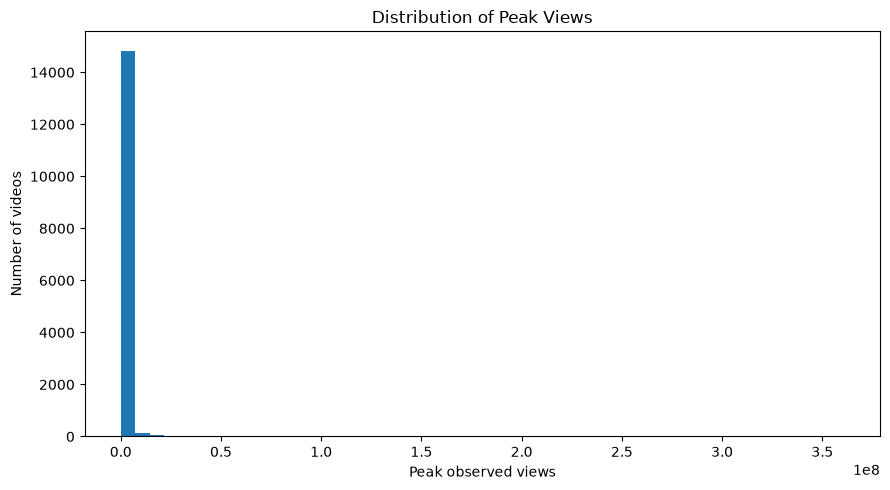

In [5]:

plt.figure(figsize=(9, 5))
plt.hist(video_summary["peak_views"].dropna(), bins=50)
plt.xlabel("Peak observed views")
plt.ylabel("Number of videos")
plt.title("Distribution of Peak Views")
plt.tight_layout()
plt.show()


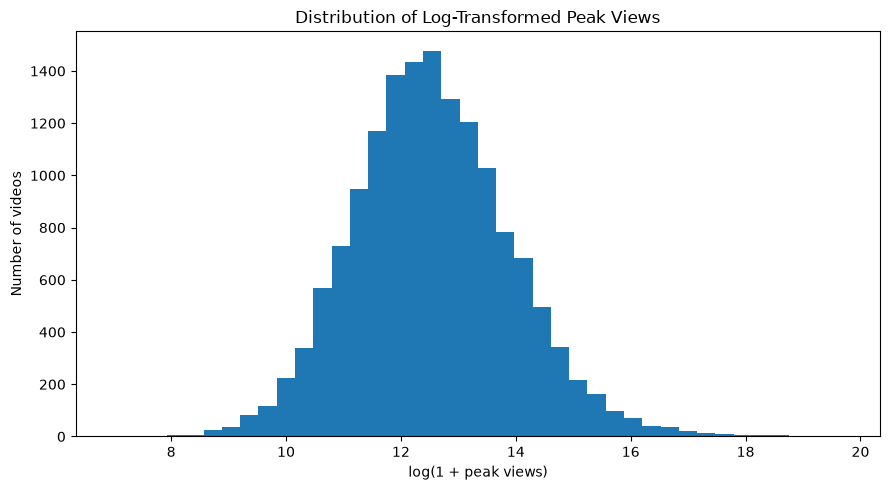

In [6]:

plt.figure(figsize=(9, 5))
plt.hist(video_summary["log_peak_views"].dropna(), bins=40)
plt.xlabel("log(1 + peak views)")
plt.ylabel("Number of videos")
plt.title("Distribution of Log-Transformed Peak Views")
plt.tight_layout()
plt.show()


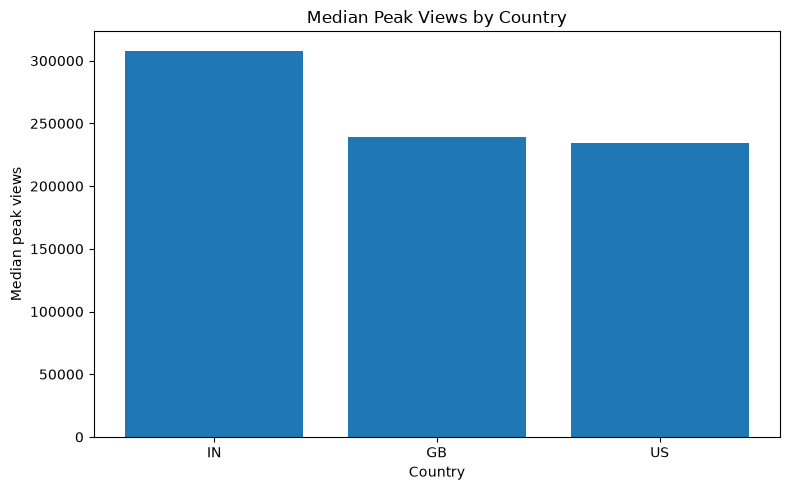

In [7]:

country_views = (
    video_summary.groupby("country")["peak_views"]
    .median()
    .sort_values(ascending=False)
)

plt.figure(figsize=(8, 5))
plt.bar(country_views.index, country_views.values)
plt.xlabel("Country")
plt.ylabel("Median peak views")
plt.title("Median Peak Views by Country")
plt.tight_layout()
plt.show()


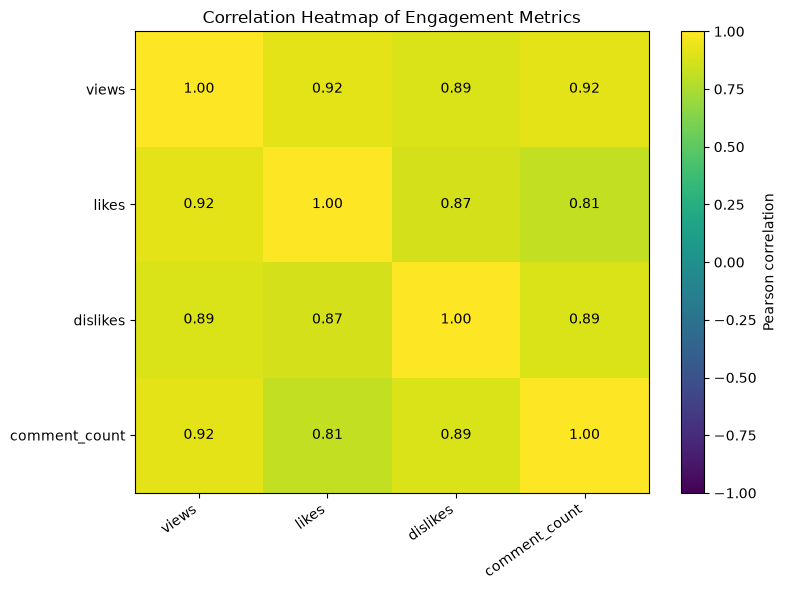

Two strongest off-diagonal pairs:
views  likes            0.92090
       comment_count    0.91547
dtype: float64


In [8]:

corr_cols = [
    "views", "likes", "dislikes", "comment_count"
]

corr_data = df[corr_cols].dropna()
corr_matrix = corr_data.corr(numeric_only=True)

plt.figure(figsize=(8, 6))
plt.imshow(corr_matrix, vmin=-1, vmax=1, aspect="auto")
plt.colorbar(label="Pearson correlation")
plt.xticks(range(len(corr_cols)), corr_cols, rotation=35, ha="right")
plt.yticks(range(len(corr_cols)), corr_cols)

for i in range(len(corr_cols)):
    for j in range(len(corr_cols)):
        plt.text(j, i, f"{corr_matrix.iloc[i, j]:.2f}",
                 ha="center", va="center")

plt.title("Correlation Heatmap of Engagement Metrics")
plt.tight_layout()
plt.show()

# Find the two strongest off-diagonal pairs by absolute correlation.
upper = corr_matrix.where(
    np.triu(np.ones(corr_matrix.shape), k=1).astype(bool)
)
pairs = upper.stack().sort_values(key=abs, ascending=False)

print("Two strongest off-diagonal pairs:")
print(pairs.head(2))


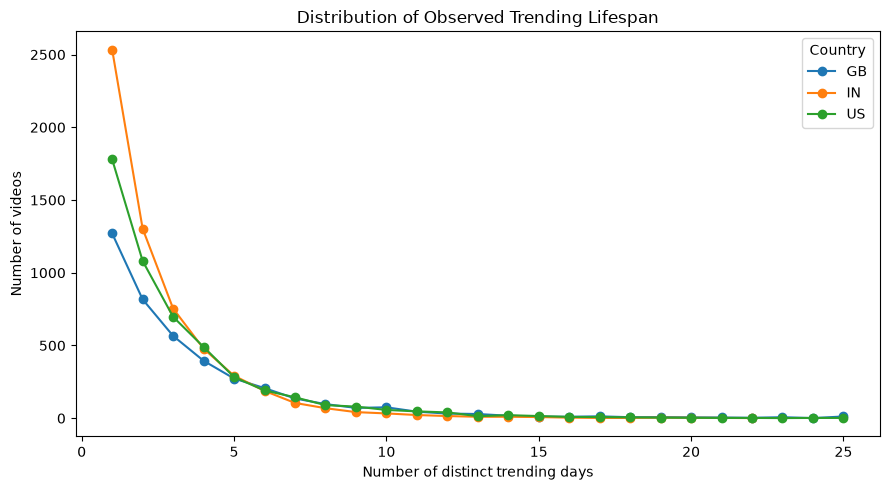

In [9]:

plt.figure(figsize=(9, 5))

for country, group in video_summary.groupby("country"):
    lifespan_counts = group["trending_days"].value_counts().sort_index()
    plt.plot(
        lifespan_counts.index,
        lifespan_counts.values,
        marker="o",
        label=country,
    )

plt.xlabel("Number of distinct trending days")
plt.ylabel("Number of videos")
plt.title("Distribution of Observed Trending Lifespan")
plt.legend(title="Country")
plt.tight_layout()
plt.show()


In [10]:

import plotly.express as px

plot_data = video_summary.dropna(
    subset=["peak_views", "likes"]
).copy()

fig = px.scatter(
    plot_data,
    x="peak_views",
    y="likes",
    color="country",
    hover_data=["video_id", "title"],
    log_x=True,
    title="Interactive: Peak Views vs Likes",
    labels={
        "peak_views": "Peak observed views (log scale)",
        "likes": "Observed likes",
    },
)
fig.show()


In [11]:

category_stats = (
    video_summary.groupby(["country", "category_id"], as_index=False)
    .agg(
        median_peak_views=("peak_views", "median"),
        video_count=("video_id", "nunique"),
    )
)

category_stats["category_id"] = category_stats["category_id"].astype(str)

fig = px.bar(
    category_stats,
    x="category_id",
    y="median_peak_views",
    color="country",
    barmode="group",
    hover_data=["video_count"],
    title="Interactive: Median Peak Views by Category and Country",
    labels={
        "category_id": "Category ID",
        "median_peak_views": "Median peak views",
    },
)
fig.show()


In [12]:

def describe_metric(series):
    x = pd.to_numeric(series, errors="coerce").dropna()

    if x.empty:
        return {"count": 0}

    q1 = x.quantile(0.25)
    q3 = x.quantile(0.75)
    iqr = q3 - q1

    outliers = x[(x < q1 - 1.5 * iqr) | (x > q3 + 1.5 * iqr)]

    return {
        "count": len(x),
        "mean": x.mean(),
        "median": x.median(),
        "mode": x.mode().iloc[0] if not x.mode().empty else np.nan,
        "Q1": q1,
        "Q3": q3,
        "IQR": iqr,
        "outlier_count": len(outliers),
        "outlier_percent": len(outliers) / len(x) * 100,
    }


for col in ["views", "likes"]:
    print(f"\n{col.upper()}")
    print(pd.Series(describe_metric(df[col])).to_string())



VIEWS
count              4.623000e+04
mean               1.178603e+06
median             3.182775e+05
mode               1.600000e+04
Q1                 1.294632e+05
Q3                 8.240505e+05
IQR                6.945872e+05
outlier_count      5.105000e+03
outlier_percent    1.104261e+01

LIKES
count              46218.000000
mean               45800.054849
median             10201.000000
mode                   0.000000
Q1                  3656.000000
Q3                 28987.750000
IQR                25331.750000
outlier_count       5292.000000
outlier_percent       11.450084


In [13]:

funnel_df = video_summary.dropna(subset=["peak_views"]).copy()

n1 = len(funnel_df)
median_views = funnel_df["peak_views"].median()
stage2 = funnel_df[funnel_df["peak_views"] > median_views]
n2 = len(stage2)

p90_views = funnel_df["peak_views"].quantile(0.90)
stage3 = stage2[stage2["peak_views"] > p90_views]
n3 = len(stage3)

stage4 = stage3[stage3["peak_comments"].fillna(0) >= 1000]
n4 = len(stage4)

stages = [
    ("Unique videos", n1),
    ("Above median peak views", n2),
    ("Above 90th percentile", n3),
    ("1,000+ comments", n4),
]

funnel_rows = []
previous = None

for label, count in stages:
    conversion = count / previous * 100 if previous else np.nan
    funnel_rows.append({
        "stage": label,
        "count": count,
        "conversion_from_previous_pct": conversion,
    })
    previous = count

funnel = pd.DataFrame(funnel_rows)
print(funnel.to_string(index=False))


                  stage  count  conversion_from_previous_pct
          Unique videos  15059                           NaN
Above median peak views   7529                     49.996680
  Above 90th percentile   1506                     20.002656
        1,000+ comments   1475                     97.941567


In [14]:

# Sort distinct observed trending dates per video-country.
date_records = (
    df[["country", "video_id", "trending_date"]]
    .dropna()
    .drop_duplicates()
    .sort_values(["country", "video_id", "trending_date"])
)

date_records["observed_day"] = (
    date_records.groupby(["country", "video_id"])
    .cumcount() + 1
)

# Each video-country pair has one record per observed trending day.
video_keys = date_records[["country", "video_id"]].drop_duplicates()
total_videos = len(video_keys)

retention_days = [2, 3, 5, 7]
retention_rows = []

for day in retention_days:
    present = date_records.loc[
        date_records["observed_day"] >= day,
        ["country", "video_id"],
    ].drop_duplicates()

    retained_count = len(present)

    retention_rows.append({
        "day": day,
        "videos_present": retained_count,
        "retention_pct": (
            retained_count / total_videos * 100
            if total_videos else np.nan
        ),
    })

retention_table = pd.DataFrame(retention_rows)
print(retention_table.to_string(index=False))


 day  videos_present  retention_pct
   2            9477      62.932466
   3            6276      41.676074
   5            2896      19.231025
   7            1462       9.708480


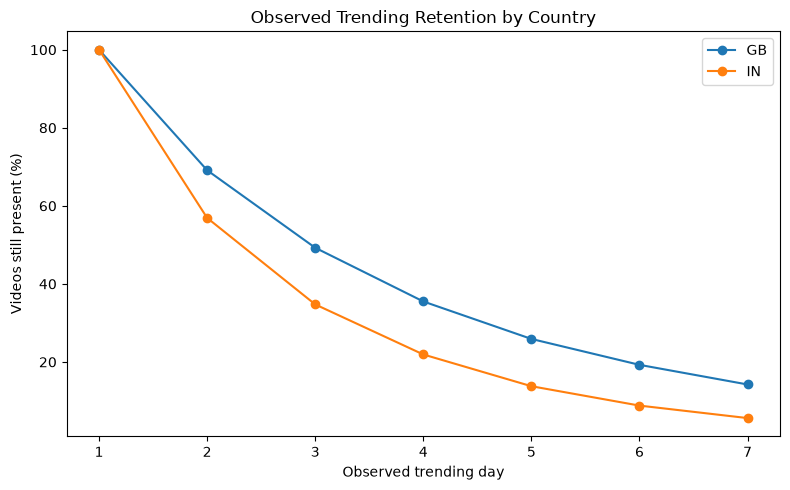

In [15]:

# Build per-country retention curves.
retention_curve_rows = []

for country, group in date_records.groupby("country"):
    total = group[["video_id"]].drop_duplicates().shape[0]

    for day in range(1, 8):
        present = group.loc[
            group["observed_day"] >= day, "video_id"
        ].nunique()

        retention_curve_rows.append({
            "country": country,
            "day": day,
            "retention_pct": present / total * 100 if total else np.nan,
        })

retention_curve = pd.DataFrame(retention_curve_rows)

countries_to_plot = retention_curve["country"].unique()[:2]
selected = retention_curve[
    retention_curve["country"].isin(countries_to_plot)
]

plt.figure(figsize=(8, 5))

for country, group in selected.groupby("country"):
    plt.plot(
        group["day"],
        group["retention_pct"],
        marker="o",
        label=country,
    )

plt.xlabel("Observed trending day")
plt.ylabel("Videos still present (%)")
plt.title("Observed Trending Retention by Country")
plt.xticks(range(1, 8))
plt.legend()
plt.tight_layout()
plt.show()


country cohort_month  cohort_size  retained_day_2_pct  retained_day_3_pct  retained_day_5_pct  retained_day_7_pct
     GB      2017-11         1090           67.889908           48.348624           25.688073           14.220183
     GB      2017-12         1644           70.863747           51.459854           27.615572           15.328467
     GB      2018-01         1379           68.020305           47.353154           24.002901           12.907904
     IN      2017-11         1414           59.759547           37.623762           14.780764            6.506365
     IN      2017-12         2356           57.512733           34.677419           14.855688            6.451613
     IN      2018-01         2108           54.316888           32.874763           11.907021            4.079696
     US      2017-11         1171           64.987190           45.687447           22.203245           11.699402
     US      2017-12         1905           67.454068           44.514436           20.8

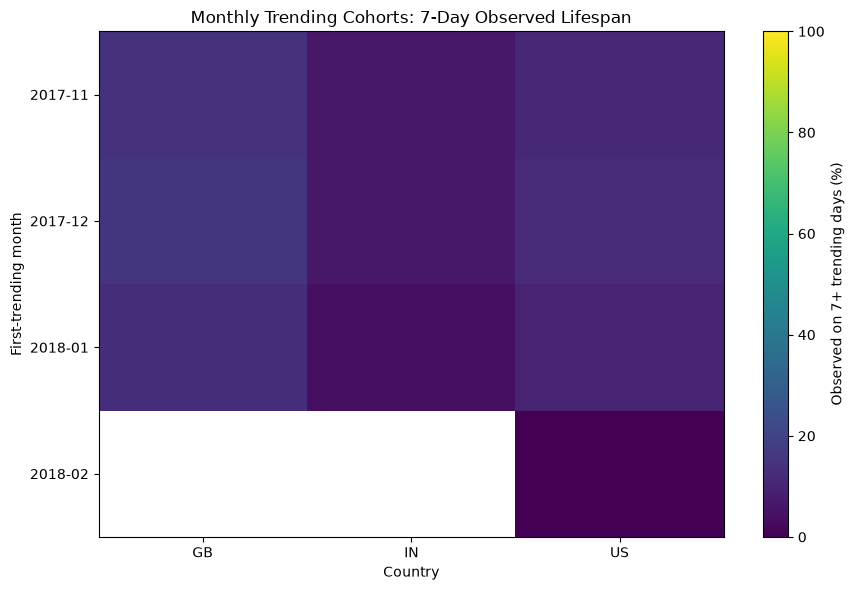

In [16]:

cohort_base = (
    date_records.groupby(["country", "video_id"], as_index=False)
    .agg(
        first_trending=("trending_date", "min"),
        lifespan=("trending_date", "nunique"),
    )
)

cohort_base["cohort_month"] = (
    cohort_base["first_trending"].dt.to_period("M").astype(str)
)

cohort_rows = []

for (country, month), group in cohort_base.groupby(
    ["country", "cohort_month"]
):
    cohort_size = len(group)

    row = {
        "country": country,
        "cohort_month": month,
        "cohort_size": cohort_size,
    }

    for day in [2, 3, 5, 7]:
        row[f"retained_day_{day}_pct"] = (
            (group["lifespan"] >= day).sum() / cohort_size * 100
            if cohort_size else np.nan
        )

    cohort_rows.append(row)

cohort_table = pd.DataFrame(cohort_rows)
print(cohort_table.to_string(index=False))

# Heatmap: percentage reaching seven distinct trending days.
cohort_pivot = cohort_table.pivot(
    index="cohort_month",
    columns="country",
    values="retained_day_7_pct",
)

plt.figure(figsize=(9, 6))
plt.imshow(cohort_pivot, aspect="auto", vmin=0, vmax=100)
plt.colorbar(label="Observed on 7+ trending days (%)")
plt.xticks(
    range(len(cohort_pivot.columns)),
    cohort_pivot.columns,
)
plt.yticks(
    range(len(cohort_pivot.index)),
    cohort_pivot.index,
)
plt.title("Monthly Trending Cohorts: 7-Day Observed Lifespan")
plt.xlabel("Country")
plt.ylabel("First-trending month")
plt.tight_layout()
plt.show()


In [17]:

views_stats = describe_metric(df["views"])
likes_stats = describe_metric(df["likes"])

top_country = (
    video_summary.groupby("country")["peak_views"]
    .median()
    .sort_values(ascending=False)
)

strongest_pairs = pairs.head(2)

funnel_conversion = (
    n4 / n1 * 100 if n1 else np.nan
)

first_month = cohort_base["first_trending"].min()
last_month = cohort_base["first_trending"].max()

print(
    f"The analysis contains {len(df):,} trending records "
    f"representing {len(video_summary):,} video-country pairs "
    f"across {video_summary['country'].nunique()} countries."
)

print(
    f"Peak views had a mean of {views_stats['mean']:,.0f} "
    f"and a median of {views_stats['median']:,.0f}; "
    f"the IQR rule identified {views_stats['outlier_count']:,} "
    f"view outliers."
)

print(
    f"Likes had a mean of {likes_stats['mean']:,.0f} "
    f"and a median of {likes_stats['median']:,.0f}, "
    f"with {likes_stats['outlier_count']:,} IQR outliers."
)

if len(top_country):
    print(
        f"{top_country.index[0]} had the highest median peak views "
        f"among the countries in this dataset "
        f"({top_country.iloc[0]:,.0f})."
    )

for (a, b), value in strongest_pairs.items():
    print(f"The correlation between {a} and {b} was {value:.3f}.")

print(
    f"The sequential funnel decreased from {n1:,} initial "
    f"video-country pairs to {n4:,} reaching the 1,000-comment "
    f"stage ({funnel_conversion:.2f}% of the initial population)."
    if n1 else "The funnel could not be calculated because no videos were available."
)

if not retention_table.empty:
    day7 = retention_table.loc[
        retention_table["day"] == 7, "retention_pct"
    ].iloc[0]
    print(f"{day7:.2f}% of video-country pairs were observed on at least seven distinct trending days.")

print(
    f"The observed first-trending period runs from {first_month} "
    f"to {last_month}."
)

print(
    "Limitation: this dataset includes videos that trended, not all "
    "YouTube videos, so the findings cannot represent the entire platform."
)


The analysis contains 46,230 trending records representing 15,059 video-country pairs across 3 countries.
Peak views had a mean of 1,178,603 and a median of 318,278; the IQR rule identified 5,105 view outliers.
Likes had a mean of 45,800 and a median of 10,201, with 5,292 IQR outliers.
IN had the highest median peak views among the countries in this dataset (308,022).
The correlation between views and likes was 0.921.
The correlation between views and comment_count was 0.915.
The sequential funnel decreased from 15,059 initial video-country pairs to 1,475 reaching the 1,000-comment stage (9.79% of the initial population).
9.71% of video-country pairs were observed on at least seven distinct trending days.
The observed first-trending period runs from 2017-11-14 00:00:00 to 2018-02-01 00:00:00.
Limitation: this dataset includes videos that trended, not all YouTube videos, so the findings cannot represent the entire platform.
